In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

## 회귀선이 있는 산점도

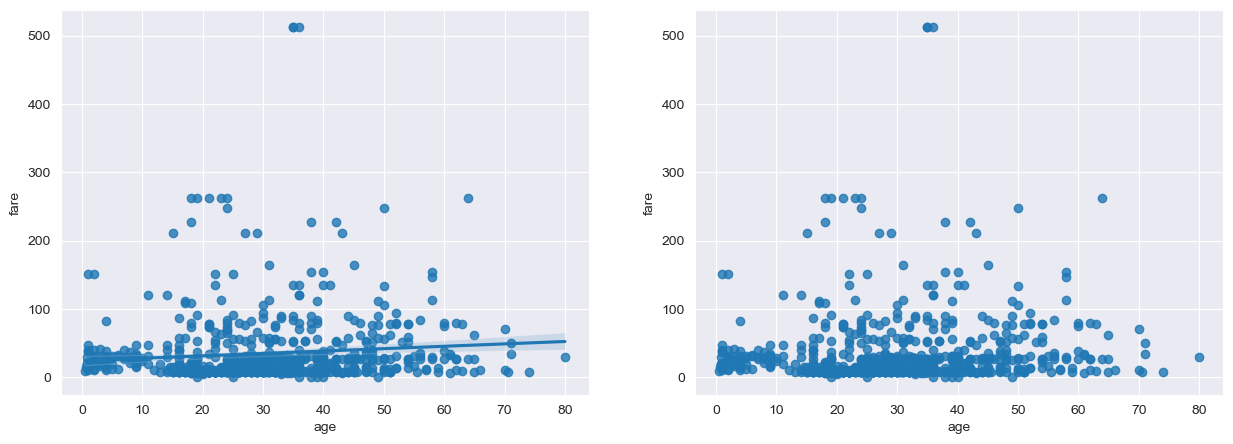

In [2]:
titanic = sns.load_dataset("titanic")

# 스타일 테마 설정
sns.set_style("darkgrid")

fig = plt.figure(figsize = (15, 5))
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2)

# 선형회귀선 표시
sns.regplot(x = "age", # x축 변수
            y = "fare", # y축 변수
            data = titanic, # 데이터
            ax = ax1) # axe 객체 - 1번째 그래프

# 선형회귀선 미표시
sns.regplot(x = "age",
            y = "fare",
            data = titanic,
            ax = ax2,
            fit_reg = False) # 회귀선 미표시 
plt.show()

# 히스토그램/커널 밀도 그래프

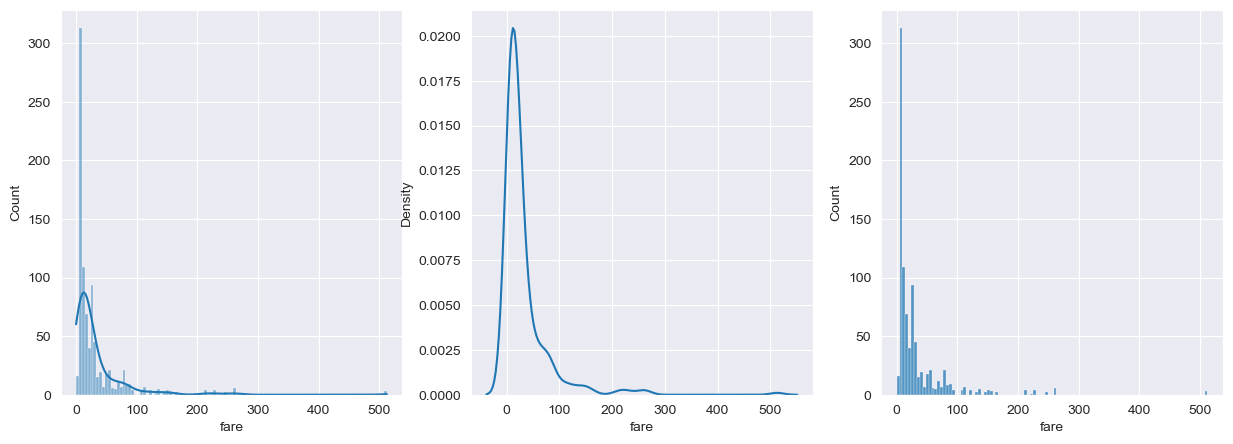

In [3]:
fig = plt.figure(figsize = (15, 5))
ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2)
ax3 = fig.add_subplot(1, 3, 3)

sns.histplot(titanic["fare"], ax = ax1, kde = True)
sns.kdeplot(x = "fare", data = titanic, ax = ax2)
sns.histplot(x = "fare", data = titanic, ax = ax3)

plt.show()

## 히트맵

- 2개의 범주형 변수를 각각 x축, y축에 놓고 데이터를 행렬 형태로 분류하여 시각화

In [6]:
# 피벗테이블로 범주형 변수를 각각 행, 열로 재구분하여 정리
table = titanic.pivot_table(index = "sex", columns = "class", aggfunc = "size", observed = False)

In [7]:
table

class,First,Second,Third
sex,,,
female,94,76,144
male,122,108,347


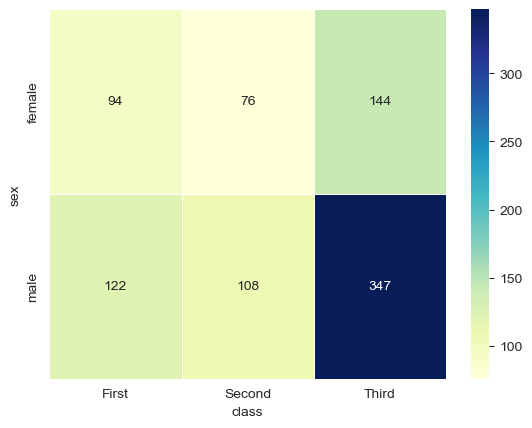

In [20]:
# 히트맵 그리기
sns.heatmap(table, # 데이터프레임
            annot = True, fmt = "d", # 데이터 값 표시 여부, 정수형 포맷
            linewidth = .5, # 구분 선
            cbar = True, # 컬러 바 표시 여부
            cmap = "YlGnBu") # 컬러 맵 
plt.show()

## 범주형 데이터의 산점도

- 범주형 변수에 들어 있는 각 범주별 데이터의 분포를 확인
    - stripplot()
        - 데이터 분산 미고려(중복 표시 있음)
     
    - swarmplot()
        - 데이터의 분산을 고려하여 데이터 포인트가 서로 중복되지 않도록 시각화
        - 데이터가 퍼져 있는 정도를 입체적으로 볼 수 있음

In [21]:
sns.set_style("whitegrid")

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 12.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


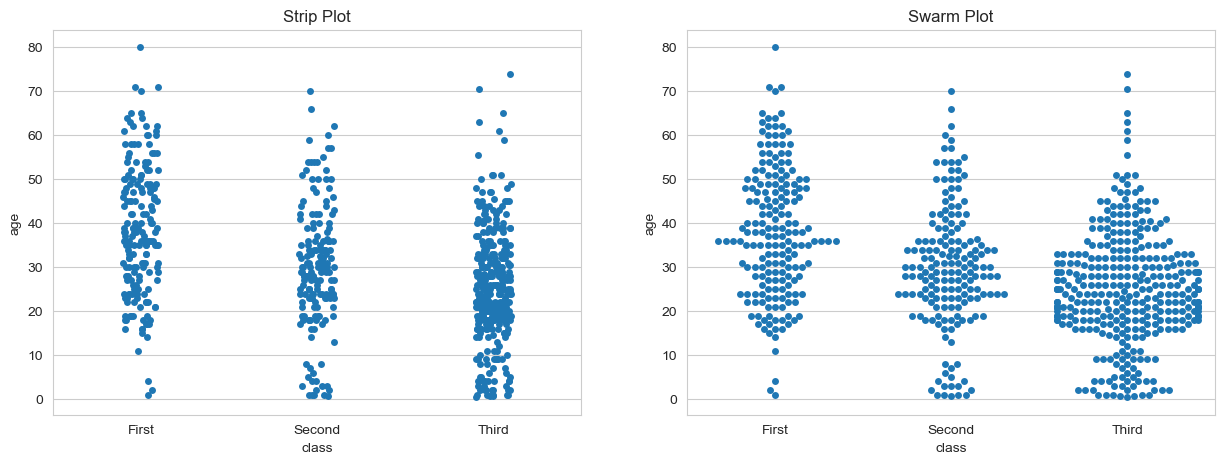

In [24]:
fig = plt.figure(figsize = (15, 5))
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2)

# 이산형 변수의 분포 - 데이터 분산 미고려
sns.stripplot(x = "class", # x축 변수
              y = "age", # y축 변수
              data = titanic, # 데이터셋
              ax = ax1) # axe 객체 - 1번째 그래프

# 이산형 변수의 분포 - 데이터 분산 고려(중복 X)
sns.swarmplot(x = "class",
              y = "age",
              data = titanic,
              ax = ax2)

ax1.set_title("Strip Plot")
ax2.set_title("Swarm Plot")
plt.show()

## 막대 그래프

In [26]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


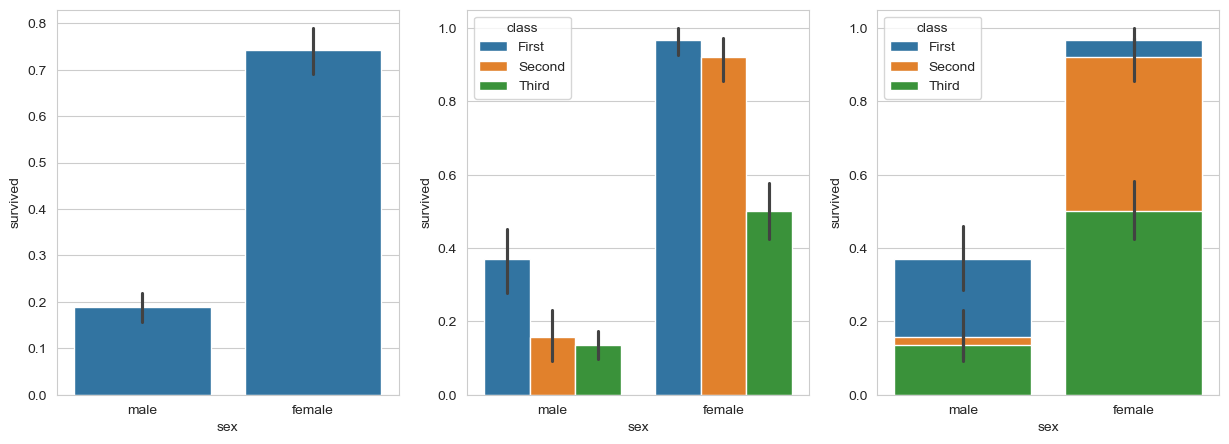

In [25]:
fig = plt.figure(figsize = (15, 5))
ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2)
ax3 = fig.add_subplot(1, 3, 3)

sns.barplot(x = "sex", y = "survived", data = titanic, ax = ax1)
sns.barplot(x = "sex", y = "survived", hue = "class", data = titanic, ax = ax2)
sns.barplot(x = "sex", y = "survived", hue = "class", dodge = False, data = titanic, ax = ax3)

plt.show()

## 빈도 그래프

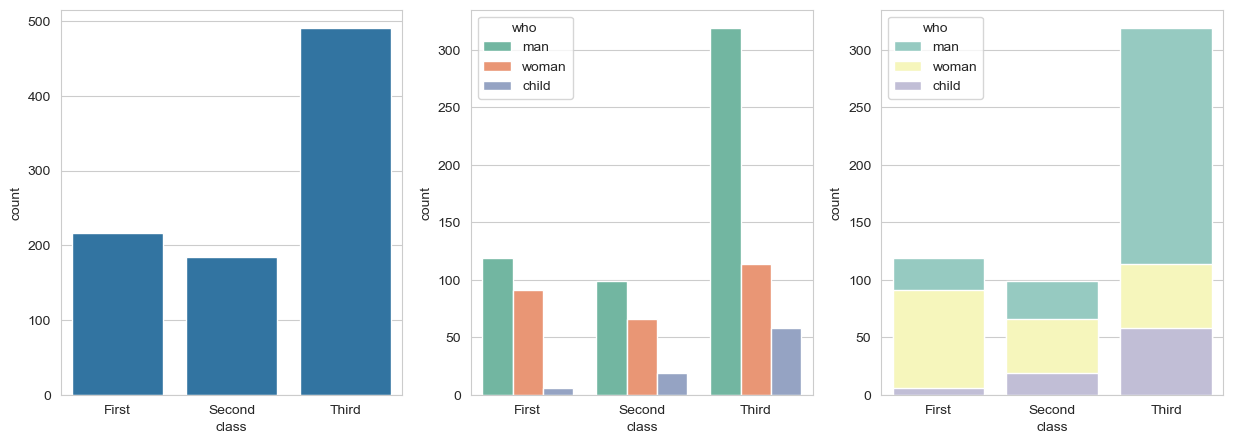

In [28]:
fig = plt.figure(figsize = (15, 5))
ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2)
ax3 = fig.add_subplot(1, 3, 3)

# 기본 빈도 그래프
sns.countplot(x = "class", data = titanic, ax = ax1)
# hue 옵션에 "who" 추가
sns.countplot(x = "class", hue = "who", palette = "Set2", data = titanic, ax = ax2)
# dodge = False 옵션 추가(축 방향으로 분리하지 않고 누적 그래프 출력)
sns.countplot(x = "class", hue = "who", palette = "Set3", dodge = False, data = titanic, ax = ax3)

plt.show()

## 박스 플롯 / 바이올린 그래프

- 박스 플롯 : 범주형 데이터 분포와 주요 통계 지표를 함께 제공
    - 다만 박스 플롯 만으로는 데이터가 퍼져 있는 분산의 정도를 정확하게 알기 어렵기 때문에 커널 밀도 함수 그래프를 y축 방향에 추가하여 바이올린 그래프를 그리는 경우도 있음

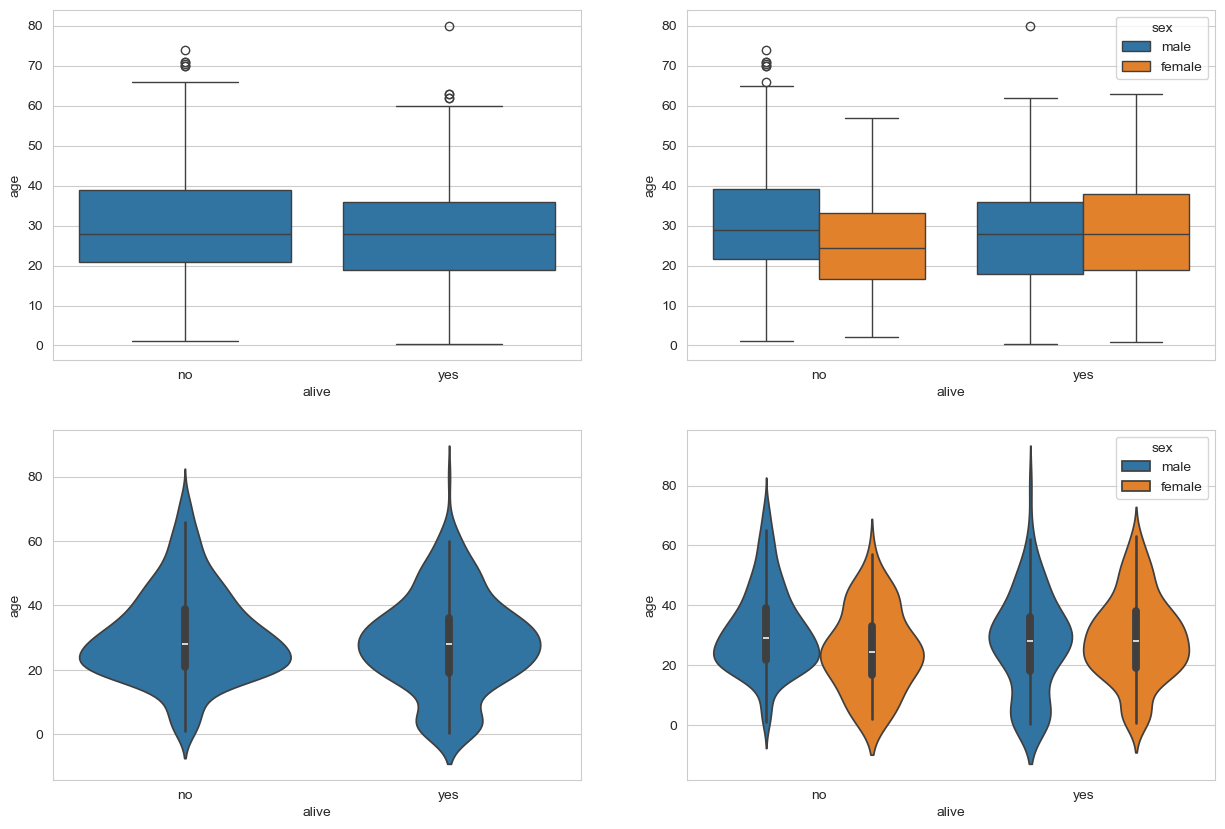

In [29]:
fig = plt.figure(figsize = (15, 10))
ax1 = fig.add_subplot(2, 2, 1)
ax2 = fig.add_subplot(2, 2, 2)
ax3 = fig.add_subplot(2, 2, 3)
ax4 = fig.add_subplot(2, 2, 4)

sns.boxplot(x = "alive", y = "age", data = titanic, ax = ax1)
sns.boxplot(x = "alive", y = "age", hue = "sex", data = titanic, ax = ax2)
sns.violinplot(x = "alive", y = "age", data = titanic, ax = ax3)
sns.violinplot(x = "alive", y = "age", hue = "sex", data = titanic, ax = ax4)

plt.show()

## 조인트 그래프

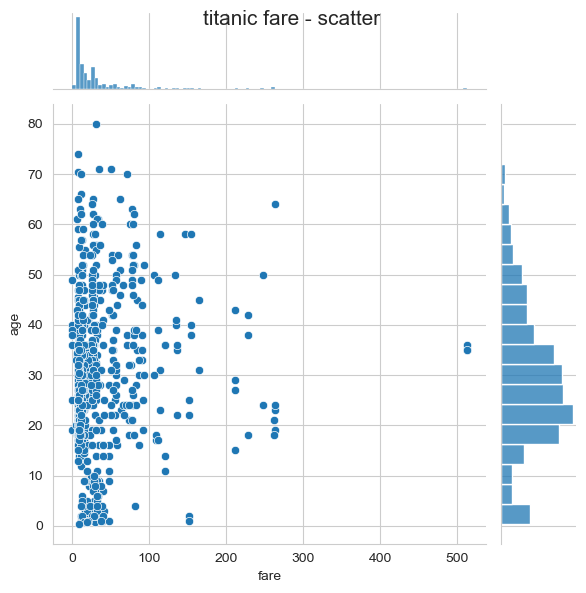

In [30]:
# 조인트 그래프 - 산점도(기본값)
j1 = sns.jointplot(x = "fare", y = "age", data = titanic)
j1.fig.suptitle("titanic fare - scatter", size = 15)
plt.show()

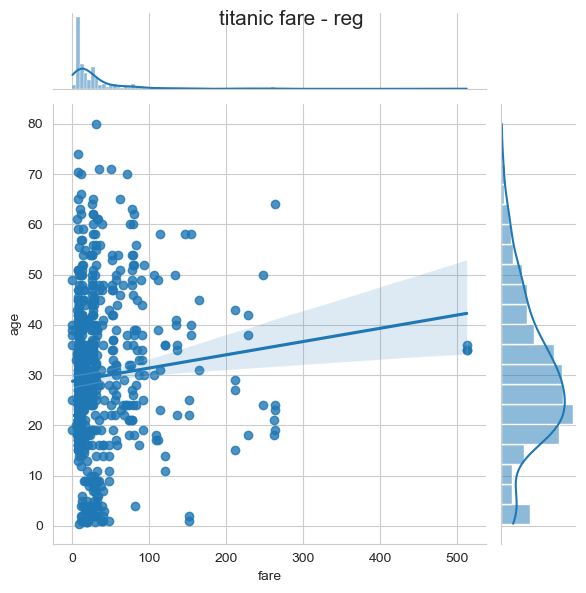

In [32]:
# 조인트 그래프 - 회귀선
j2 = sns.jointplot(x = "fare", y = "age", kind = "reg", data = titanic)
j2.fig.suptitle("titanic fare - reg", size = 15)
plt.show()

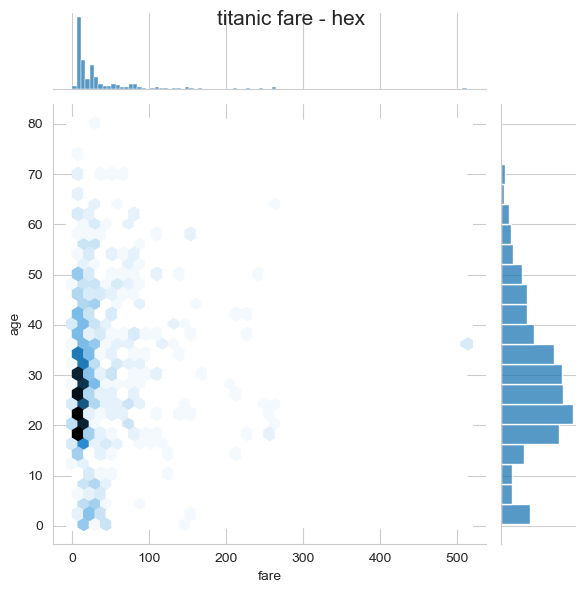

In [34]:
# 조인트 그래프 - 육각 그래프
j3 = sns.jointplot(x = "fare", y = "age", kind = "hex", data = titanic)
j3.fig.suptitle("titanic fare - hex", size = 15)
plt.show()

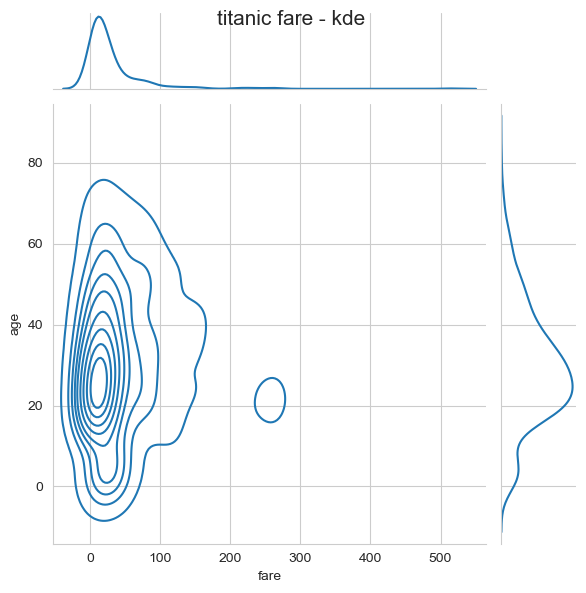

In [35]:
# 조인트 그래프 - 커널 밀집 그래프
j4 = sns.jointplot(x = "fare", y = "age", kind = "kde", data = titanic)
j4.fig.suptitle("titanic fare - kde", size = 15)
plt.show()